In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/sales_data_sample.csv',
                 encoding='unicode_escape')
print(df.head())
print(df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [ ]:
from sklearn.preprocessing import StandardScaler
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES',
            'MSRP', 'MONTH_ID', 'YEAR_ID']
X = df[features].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Preprocessing completed:", X_scaled.shape)

Preprocessing completed: (2823, 6)


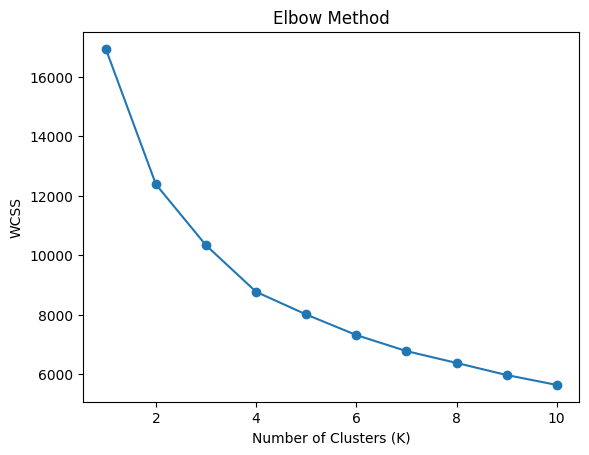

In [ ]:
from sklearn.cluster import KMeans
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

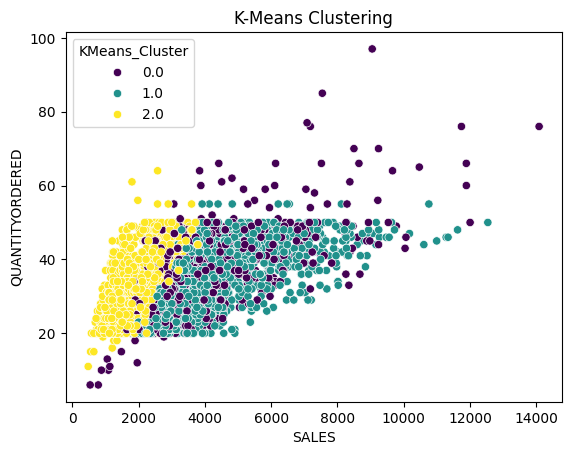

     SALES  QUANTITYORDERED  KMeans_Cluster
0  2871.00               30             1.0
1  2765.90               34             2.0
2  3884.34               41             1.0
3  3746.70               45             1.0
4  5205.27               49             1.0


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df.loc[X.index, 'KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
sns.scatterplot(
    x=X['SALES'], y=X['QUANTITYORDERED'],
    hue=df.loc[X.index, 'KMeans_Cluster'],
    palette='viridis'
)
plt.title('K-Means Clustering')
plt.show()
print(df[['SALES', 'QUANTITYORDERED',
          'KMeans_Cluster']].head())

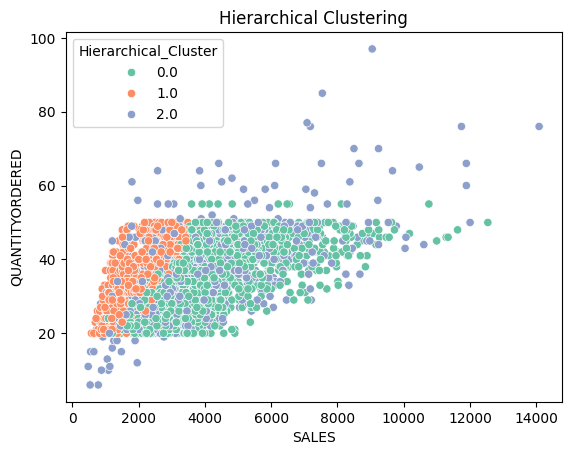

     SALES  QUANTITYORDERED  Hierarchical_Cluster
0  2871.00               30                   0.0
1  2765.90               34                   0.0
2  3884.34               41                   0.0
3  3746.70               45                   0.0
4  5205.27               49                   0.0


In [ ]:
from sklearn.cluster import AgglomerativeClustering
hierarchical = AgglomerativeClustering(n_clusters=3)
df.loc[X.index, 'Hierarchical_Cluster'] = (
    hierarchical.fit_predict(X_scaled)
)
sns.scatterplot(
    x=X['SALES'], y=X['QUANTITYORDERED'],
    hue=df.loc[X.index, 'Hierarchical_Cluster'],
    palette='Set2'
)
plt.title('Hierarchical Clustering')
plt.show()
print(df[['SALES', 'QUANTITYORDERED',
          'Hierarchical_Cluster']].head())